# Automated Authentication of Van Gogh Paintings
### Through Image Processing and Feature Engineering (ARTI 403, Group 3)


---
# PART 1: PRE-PROCESSING
## 0. Setup

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from joblib import Parallel, delayed, dump
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops
from skimage.measure import shannon_entropy

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
                                     GridSearchCV, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None         
sns.set_theme(style="whitegrid")
SEED = 42

### Configuration
**Label scheme:** `0 = authentic`, `1 = counterfeit / non-authentic`. 

In [2]:
DATA_ROOT = Path(".")               
WORK_DIR  = Path("work")
STD_DIR   = WORK_DIR / "standardized"  
FEAT_DIR  = WORK_DIR / "features"      
for d in (STD_DIR, FEAT_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "authentic", 1: "counterfeit/non-van Gogh"}
# Folder-based sources: every image in the folder gets the same label.
SOURCES = [
    dict(folder="Vincent Forgeries Wacker", source="VG-Auth", subtype="wacker_forgery",      label=1),
    dict(folder="Vincent Stable Diffusion", source="VG-Auth", subtype="stable_diffusion",    label=1),
    dict(folder="Vincent GAN finetune",     source="VG-Auth", subtype="stylegan3_finetuned", label=1),
    dict(folder="Vincent GAN random",       source="VG-Auth", subtype="stylegan3_random",    label=1),
]

VGDB = dict(folder="vgdb_2016",
            csv="vgdb_2016.csv",
            sets=("train", "test", "check"),   # subfolders to read
            id_col="id",                        # CSV column that matches the image file name (without extension)
            label_col="label",                  # CSV column that says whether it is a van Gogh
            vangogh_value="vangogh",            # the value in label_col that means "van Gogh"
            label_vangogh=0,                    # label given to van Gogh paintings (authentic)
            label_other=1)                      # label for other artists (None = exclude them)
IMG_EXT = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}


MAIN_CFG = "enhanced"        # the variant used for the main classifiers

TEST_SIZE = 0.2
N_JOBS    = 2                # raise if you have the RAM/cores (large PNGs need ~1.5 GB each while loading)
FORCE_RECOMPUTE = False      # True = ignore cached standardised images / feature tables

## 1. Data loading and labelling
Builds one metadata table (one row per painting). It records the source, sub-type, label, and the image size and format. Size and format matter because the two datasets differ a lot (23k px PNGs vs 512 px StyleGAN images), which can leak the label through resolution alone.

In [3]:
def _fake_painting(r, w, h, authentic):
    canvas = np.full((h, w, 3), r.integers(80, 170, 3), np.uint8)
    for _ in range(1500):
        x, y = int(r.integers(0, w)), int(r.integers(0, h))
        ang = np.pi / 4 + r.normal(0, 0.3) if authentic else r.uniform(0, np.pi)
        length = int(r.integers(15, 40)) if authentic else int(r.integers(5, 15))
        col = tuple(int(c) for c in np.clip(canvas[y, x].astype(int) + r.integers(-60, 60, 3), 0, 255))
        cv2.line(canvas, (x, y), (int(x + length * np.cos(ang)), int(y + length * np.sin(ang))),
                 col, 3 if authentic else 2)
    return canvas

In [4]:
def build_metadata(sources, root):
    rows = []
    for s in sources:
        if s["label"] is None:
            continue
        folder = Path(root) / s["folder"]
        if not folder.exists():
            print(f"[warn] folder not found, skipping: {folder}")
            continue
        for p in sorted(folder.rglob("*")):
            if p.suffix.lower() in IMG_EXT:
                with Image.open(p) as im:          # reads the header only, not the pixels
                    w, h = im.size
                rows.append(dict(path=str(p), source=s["source"], subtype=s["subtype"],
                                 label=s["label"], width=w, height=h, fmt=p.suffix.lower().lstrip(".")))
    if not rows:
        raise FileNotFoundError("No images found. Check DATA_ROOT / SOURCES, or set USE_SYNTHETIC_DEMO = True.")
    df = pd.DataFrame(rows)
    df.insert(0, "painting_id", [f"P{i:04d}" for i in range(len(df))])
    return df

meta = build_metadata(SOURCES, DATA_ROOT)
print(f"{len(meta)} paintings loaded")
meta.head()

99 paintings loaded


,painting_id,path,source,subtype,label,width,height,fmt
0,P0000,Vincent Forgeries Wacker\108801.jpg,VG-Auth,wacker_forgery,1,776,600,jpg
1,P0001,Vincent Forgeries Wacker\1231.jpg,VG-Auth,wacker_forgery,1,2352,2864,jpg
2,P0002,Vincent Forgeries Wacker\1969141.jpg,VG-Auth,wacker_forgery,1,2400,2912,jpg
3,P0003,Vincent Forgeries Wacker\230942.jpg,VG-Auth,wacker_forgery,1,733,958,jpg
4,P0004,Vincent Forgeries Wacker\46628.jpg,VG-Auth,wacker_forgery,1,3194,4000,jpg


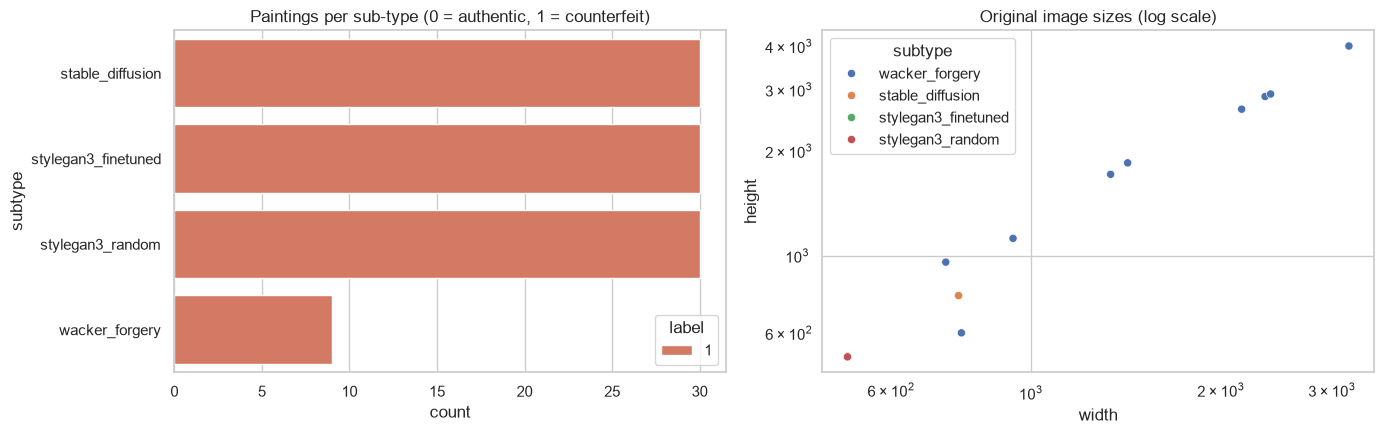

Sub-type x file-format table (a strong imbalance here is a potential shortcut for the classifier):


fmt,jpg,png
subtype,,
stable_diffusion,30,0
stylegan3_finetuned,0,30
stylegan3_random,0,30
wacker_forgery,9,0


Median size per sub-type:


,width,height
subtype,,
stable_diffusion,768.0,768.0
stylegan3_finetuned,512.0,512.0
stylegan3_random,512.0,512.0
wacker_forgery,1424.0,1847.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

order = meta.groupby("subtype").size().sort_values(ascending=False).index
sns.countplot(data=meta, y="subtype", hue="label", order=order, ax=axes[0], dodge=False,
              palette={0: "#2a9d8f", 1: "#e76f51"})
axes[0].set_title("Paintings per sub-type (0 = authentic, 1 = counterfeit)")

sns.scatterplot(data=meta, x="width", y="height", hue="subtype", ax=axes[1], s=35)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Original image sizes (log scale)")
plt.tight_layout(); plt.show()

print("Sub-type x file-format table (a strong imbalance here is a potential shortcut for the classifier):")
display(pd.crosstab(meta["subtype"], meta["fmt"]))
print("Median size per sub-type:")
display(meta.groupby("subtype")[["width", "height"]].median())

## 2. Train / test split (at painting level)
The split is made **before** any patches are extracted, so patches from one painting can never appear in both train and test (data leakage, see reference [4]). Stratifying by sub-type keeps the rare classes, such as the 9 Wacker forgeries, in both sets.

In [6]:
strat = meta["subtype"] if meta["subtype"].value_counts().min() >= 2 else meta["label"]
train_ids, test_ids = train_test_split(meta["painting_id"], test_size=TEST_SIZE,
                                       stratify=strat, random_state=SEED)
meta["split"] = np.where(meta["painting_id"].isin(set(train_ids)), "train", "test")

assert set(train_ids).isdisjoint(set(test_ids))
print(pd.crosstab(meta["subtype"], meta["split"], margins=True))
meta.to_csv(WORK_DIR / "metadata.csv", index=False)

split                test  train  All
subtype                              
stable_diffusion        6     24   30
stylegan3_finetuned     6     24   30
stylegan3_random        6     24   30
wacker_forgery          2      7    9
All                    20     79   99


## 3. Image pre-processing and enhancement 

<img src="Diagrams/preprocessing_pipeline.png" width="1000">

In [7]:
# Create folders for processed images
RESIZED_DIR = WORK_DIR / "resized"
ENHANCED_DIR = WORK_DIR / "enhanced"

RESIZED_DIR.mkdir(parents=True, exist_ok=True)
ENHANCED_DIR.mkdir(parents=True, exist_ok=True)

In [8]:
def preprocess_image(path):
    img = cv2.imread(str(path))

    if img is None:
        raise ValueError(f"Cannot read: {path}")

    # Resize the image to the same size
    img = cv2.resize(img, (256, 256))

    # Reduce noise using Gaussian filtering
    img = cv2.GaussianBlur(img, (3, 3), 0)

    # Improve brightness contrast using LAB color space
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    # Apply histogram equalization to brightness (l)
    l = cv2.equalizeHist(l)

    # Combine the channels
    enhanced = cv2.merge((l, a, b))
    enhanced = cv2.cvtColor(enhanced, cv2.COLOR_LAB2BGR)

    return img, enhanced

In [9]:
# Process all images in the dataset
processed_rows = []

for _, row in meta.iterrows():
    try:
        resized, enhanced = preprocess_image(row["path"])
        image_id = str(row["painting_id"])

        # Save both image versions
        resized_path = RESIZED_DIR / f"{image_id}.png"
        enhanced_path = ENHANCED_DIR / f"{image_id}.png"

        cv2.imwrite(str(resized_path), resized)
        cv2.imwrite(str(enhanced_path), enhanced)

        processed_rows.append({
            "painting_id": image_id,
            "resized_path": str(resized_path),
            "enhanced_path": str(enhanced_path)
        })

    except Exception as e:
        print("Skipped:", row["path"], e)

# Add processed paths to metadata
processed_df = pd.DataFrame(processed_rows)
meta = meta.drop(
    columns=["resized_path", "enhanced_path"],
    errors="ignore"
).merge(processed_df, on="painting_id", how="left")

print("Processed images:", len(processed_df))
display(processed_df.head())

Processed images: 99


,painting_id,resized_path,enhanced_path
0,P0000,work\resized\P0000.png,work\enhanced\P0000.png
1,P0001,work\resized\P0001.png,work\enhanced\P0001.png
2,P0002,work\resized\P0002.png,work\enhanced\P0002.png
3,P0003,work\resized\P0003.png,work\enhanced\P0003.png
4,P0004,work\resized\P0004.png,work\enhanced\P0004.png


All paintings are resized to a standard size, smoothed to reduce noise, and enhanced using histogram equalization on the LAB lightness channel. This prepares the images for further processing and feature extraction.

## 4. Segmentation into patches / regions

<img src="Diagrams/segmentation_pipeline.png" width="1000">

In [10]:
# Create a folder for image patches
PATCH_DIR = WORK_DIR / "patches"
PATCH_DIR.mkdir(parents=True, exist_ok=True)

In [11]:
patch_rows = []

# Process every enhanced image
for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    img = cv2.imread(str(row["enhanced_path"]))
    painting_id = str(row["painting_id"])

    # Divide each image into 64x64 patches
    for y in range(0, 256, 64):
        for x in range(0, 256, 64):

            patch = img[y:y+64, x:x+64]

            # Save each patch
            patch_path = PATCH_DIR / f"{painting_id}_{y}_{x}.png"
            cv2.imwrite(str(patch_path), patch)

            patch_rows.append({
                "painting_id": painting_id,
                "patch_path": str(patch_path),
                "x": x,
                "y": y
            })

# Create patch metadata
patches_df = pd.DataFrame(patch_rows)

print("Total patches:", len(patches_df))
display(patches_df.head())

Total patches: 1584


,painting_id,patch_path,x,y
0,P0000,work\patches\P0000_0_0.png,0,0
1,P0000,work\patches\P0000_0_64.png,64,0
2,P0000,work\patches\P0000_0_128.png,128,0
3,P0000,work\patches\P0000_0_192.png,192,0
4,P0000,work\patches\P0000_64_0.png,0,64


Each enhanced painting is divided into 16 non-overlapping patches of size 64 × 64 pixels. This helps analyze local details such as texture and brushstroke patterns in different regions of the painting.

## 5. Edge detection and morphological processing

<img src="Diagrams/edgedetection_pipeline.png" width="1000">

In [12]:
# Create folders for edge results
EDGE_DIR = WORK_DIR / "edges"
MORPH_DIR = WORK_DIR / "morphology"

EDGE_DIR.mkdir(parents=True, exist_ok=True)
MORPH_DIR.mkdir(parents=True, exist_ok=True)

In [13]:
edge_rows = []

# Create a kernel for morphology
kernel = np.ones((3, 3), np.uint8)

for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    img = cv2.imread(str(row["enhanced_path"]))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Detect image edges
    edges = cv2.Canny(gray, 100, 200)

    # Apply dilation and erosion
    dilated = cv2.dilate(edges, kernel, iterations=1)
    eroded = cv2.erode(dilated, kernel, iterations=1)

    # Save the results
    image_id = str(row["painting_id"])

    edge_path = EDGE_DIR / f"{image_id}.png"
    morph_path = MORPH_DIR / f"{image_id}.png"

    cv2.imwrite(str(edge_path), edges)
    cv2.imwrite(str(morph_path), eroded)

    # Calculate edge features
    edge_rows.append({
        "painting_id": image_id,
        "edge_path": str(edge_path),
        "morph_path": str(morph_path),
        "edge_density": np.mean(edges > 0),
        "morph_density": np.mean(eroded > 0)
    })

edges_df = pd.DataFrame(edge_rows)

print("Images analyzed:", len(edges_df))
display(edges_df.head())

Images analyzed: 99


,painting_id,edge_path,morph_path,edge_density,morph_density
0,P0000,work\edges\P0000.png,work\morphology\P0000.png,0.301575,0.631012
1,P0001,work\edges\P0001.png,work\morphology\P0001.png,0.180069,0.335464
2,P0002,work\edges\P0002.png,work\morphology\P0002.png,0.286453,0.582733
3,P0003,work\edges\P0003.png,work\morphology\P0003.png,0.247055,0.478760
4,P0004,work\edges\P0004.png,work\morphology\P0004.png,0.317383,0.672241


Canny edge detection is applied to identify painting edges, followed by dilation and erosion to refine them.

**Edge density** and **morphological density** are extracted to help the model learn differences in texture, brushstrokes, and structural patterns between authentic and forged paintings.

## 6. Colour processing and feature extraction

<img src="Diagrams/featureextraction_pipeline.png" width="1000">

In [14]:
def extract_features(img):

    # Convert image to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    features = {}

    # Color features
    for i, color in enumerate(["B", "G", "R"]):
        features[f"{color}_mean"] = np.mean(img[:, :, i])
        features[f"{color}_std"] = np.std(img[:, :, i])

    # Intensity features
    features["intensity_mean"] = np.mean(gray)
    features["intensity_std"] = np.std(gray)

    # Local texture using LBP
    lbp = local_binary_pattern(
        gray, P=8, R=1, method="uniform"
    )

    features["lbp_mean"] = np.mean(lbp)
    features["lbp_std"] = np.std(lbp)

    # Texture using GLCM
    glcm = graycomatrix(
        gray,
        distances=[1],
        angles=[0],
        levels=256,
        symmetric=True,
        normed=True
    )

    features["contrast"] = graycoprops(glcm, "contrast")[0, 0]
    features["homogeneity"] = graycoprops(glcm, "homogeneity")[0, 0]
    features["energy"] = graycoprops(glcm, "energy")[0, 0]

    # Image information
    features["entropy"] = shannon_entropy(gray)

    return features

In [15]:
# Extract features from all paintings
feature_rows = []

for _, row in meta.dropna(subset=["enhanced_path"]).iterrows():

    image_id = str(row["painting_id"])

    # Read the full processed painting
    img = cv2.imread(str(row["enhanced_path"]))

    # Extract full-image features
    features = extract_features(img)

    # Find patches belonging to this painting
    painting_patches = patches_df[
        patches_df["painting_id"] == image_id
    ]

    patch_features = []

    # Extract features from all patches
    for patch_path in painting_patches["patch_path"]:

        patch = cv2.imread(str(patch_path))
        patch_features.append(extract_features(patch))

    # Calculate average patch features
    if patch_features:
        patch_mean = pd.DataFrame(patch_features).mean()

        for name, value in patch_mean.items():
            features[f"patch_{name}"] = value

    features["painting_id"] = image_id
    feature_rows.append(features)

# Create the feature table
features_df = pd.DataFrame(feature_rows)

print("Paintings with features:", len(features_df))
display(features_df.head())

Paintings with features: 99


,B_mean,B_std,G_mean,G_std,R_mean,R_std,intensity_mean,intensity_std,lbp_mean,lbp_std,...,patch_R_std,patch_intensity_mean,patch_intensity_std,patch_lbp_mean,patch_lbp_std,patch_contrast,patch_homogeneity,patch_energy,patch_entropy,painting_id
0,95.714615,62.568395,127.850220,71.729307,120.164978,76.705391,121.889740,71.880152,4.533646,2.271967,...,64.930244,121.889740,60.605282,4.472214,2.293404,607.246760,0.115856,0.021111,7.309300,P0000
1,63.884872,69.066078,113.578293,73.709687,153.108887,78.161561,119.739136,73.153831,4.682419,2.299793,...,59.647771,119.739136,55.834271,4.623108,2.321848,400.743505,0.195911,0.038973,6.918954,P0001
2,79.509659,69.914162,127.282227,75.515594,118.094986,71.134380,119.089615,71.580698,4.588272,2.404941,...,55.739142,119.089615,49.422026,4.525711,2.424246,365.457357,0.108333,0.023242,7.027240,P0002
3,90.085129,59.833720,119.976181,74.079581,141.201279,72.181366,122.914734,71.237608,4.520157,2.222335,...,54.231246,122.914734,53.224321,4.459412,2.248899,290.226950,0.124979,0.022269,7.133106,P0003
4,84.513809,65.187877,126.481934,72.826139,126.596619,75.734934,121.706329,72.506404,4.627655,2.429819,...,50.595465,121.706329,48.804172,4.564087,2.448546,395.740994,0.103503,0.028453,6.729041,P0004


For each enhanced painting, color, intensity, and texture features are extracted. Texture is described using LBP, GLCM, and entropy. These values are combined into one feature vector that represents each painting for later machine learning.

## 7. Build and save the feature dataset


In [16]:
# Add edge and morphology features
features_df = features_df.merge(
    edges_df[
        ["painting_id", "edge_density", "morph_density"]
    ],
    on="painting_id",
    how="left"
)

# Add painting labels and split information
features_df = features_df.merge(
    meta[
        ["painting_id", "path", "source",
         "subtype", "label", "split"]
    ],
    on="painting_id",
    how="left"
)

In [17]:
# Save the final feature dataset
output_path = FEAT_DIR / "painting_features.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)

features_df.to_csv(output_path, index=False)

# Display dataset information
print("Total paintings:", len(features_df))
print("Total columns:", features_df.shape[1])
print("Saved to:", output_path)

display(features_df.head())

Total paintings: 99
Total columns: 36
Saved to: work\features\painting_features.csv


,B_mean,B_std,G_mean,G_std,R_mean,R_std,intensity_mean,intensity_std,lbp_mean,lbp_std,...,patch_energy,patch_entropy,painting_id,edge_density,morph_density,path,source,subtype,label,split
0,95.714615,62.568395,127.850220,71.729307,120.164978,76.705391,121.889740,71.880152,4.533646,2.271967,...,0.021111,7.309300,P0000,0.301575,0.631012,Vincent Forgeries Wacker\108801.jpg,VG-Auth,wacker_forgery,1,train
1,63.884872,69.066078,113.578293,73.709687,153.108887,78.161561,119.739136,73.153831,4.682419,2.299793,...,0.038973,6.918954,P0001,0.180069,0.335464,Vincent Forgeries Wacker\1231.jpg,VG-Auth,wacker_forgery,1,train
2,79.509659,69.914162,127.282227,75.515594,118.094986,71.134380,119.089615,71.580698,4.588272,2.404941,...,0.023242,7.027240,P0002,0.286453,0.582733,Vincent Forgeries Wacker\1969141.jpg,VG-Auth,wacker_forgery,1,train
3,90.085129,59.833720,119.976181,74.079581,141.201279,72.181366,122.914734,71.237608,4.520157,2.222335,...,0.022269,7.133106,P0003,0.247055,0.478760,Vincent Forgeries Wacker\230942.jpg,VG-Auth,wacker_forgery,1,train
4,84.513809,65.187877,126.481934,72.826139,126.596619,75.734934,121.706329,72.506404,4.627655,2.429819,...,0.028453,6.729041,P0004,0.317383,0.672241,Vincent Forgeries Wacker\46628.jpg,VG-Auth,wacker_forgery,1,test


In [18]:
# Check the number of processed images
print("Original images:", len(meta))
print("Preprocessed images:", len(processed_df))
print("Images with edges:", len(edges_df))
print("Total patches:", len(patches_df))
print("Images with features:", len(features_df))

# Check for missing values
print("\nMissing feature values:")
print(features_df.isnull().sum().sum())

# Check class distribution
print("\nClass distribution:")
print(features_df["label"].value_counts())

# Check train and test distribution
print("\nTrain/Test distribution:")
print(pd.crosstab(features_df["label"], features_df["split"]))

Original images: 99
Preprocessed images: 99
Images with edges: 99
Total patches: 1584
Images with features: 99

Missing feature values:
0

Class distribution:
label
1    99
Name: count, dtype: int64

Train/Test distribution:
split  test  train
label             
1        20     79


---
# PART 2: MACHINE LEARNING MODEL
## 8. Load features and prepare data

## 9. Classifiers

## 10. Evaluation 

## 11. Comparative analysis